# 05 · Feature experiments

Same GBM, same three folds, different feature groups. The question for each group is not just "does it help on average" but "does it help in every fold", because the real test is a period the model has never seen.

## Feature-group experiments
`hard subset` = the unseen-city stress test from notebook 03.

In [1]:
import sys; sys.path.append("../src")
import pandas as pd
from gbm import GBMModel
from cv import run_cv, run_hard

raw = pd.read_csv("../data/train_test.csv")

EXPERIMENTS = {
    "A base (distance, equipment)":   ["base"],
    "B + weight":                     ["base", "weight"],
    "C + market_index":               ["base", "market_index"],
    "D + weight + market_index":      ["base", "weight", "market_index"],
    "E  D + quote_signal":            ["base", "weight", "market_index", "quote_signal"],
    "F  D + day of week/month":       ["base", "weight", "market_index", "dow_dom"],
    "G  D + month number":            ["base", "weight", "market_index", "month"],
    "H  D + coordinates":             ["base", "weight", "market_index", "coords"],
    "I  B + quote_signal (no market_index)": ["base", "weight", "quote_signal"],
    "J  B + smoothed market_index":              ["base", "weight", "market_smooth"],
    "K  J + day of week":                        ["base", "weight", "market_smooth", "dow"],
    "L  J + quote_signal":                       ["base", "weight", "market_smooth", "quote_signal"],
    "M  B + day of week":                 ["base", "weight", "dow"],
    "N  I + day of week":                 ["base", "weight", "quote_signal", "dow"],
    "O  N + month number":                ["base", "weight", "quote_signal", "dow", "month"],
    "P  B + qs month level & deviation":        ["base", "weight", "qs_month"],
    "R  B + qs deviation only":                 ["base", "weight", "qs_dev"],
    "S  M + coordinates":                       ["base", "weight", "dow", "coords"],
    "T  S + quote_signal":                      ["base", "weight", "dow", "coords", "quote_signal"],
}

rows = []
for name, groups in EXPERIMENTS.items():
    make = lambda g=groups: GBMModel(g)
    cv, hard = run_cv(make, raw), run_hard(make, raw, seeds=(0, 1, 2))
    rows.append({"experiment": name,
                 "MAE_clean cv": cv["MAE_clean"].mean(),
                 "fold1": cv.loc[1, "MAE_clean"], "fold2": cv.loc[2, "MAE_clean"],
                 "fold3": cv.loc[3, "MAE_clean"],
                 "MAPE%_clean": cv["MAPE%_clean"].mean(),
                 "hard subset": hard["MAE_clean"].mean()})

res = pd.DataFrame(rows).set_index("experiment").round(2)
display(res)

,MAE_clean cv,fold1,fold2,fold3,MAPE%_clean,hard subset
experiment,,,,,,
"A base (distance, equipment)",102.33,149.02,81.04,76.93,4.33,84.88
B + weight,89.99,144.39,66.54,59.05,3.83,64.77
C + market_index,94.25,87.08,77.64,118.02,4.04,129.25
D + weight + market_index,82.59,74.29,63.60,109.88,3.58,120.39
E D + quote_signal,70.05,54.93,82.00,73.21,3.01,82.45
F D + day of week/month,88.77,78.52,67.45,120.34,3.80,131.27
G D + month number,72.84,76.09,70.71,71.72,3.23,78.20
H D + coordinates,72.76,60.50,51.50,106.28,3.04,115.51
I B + quote_signal (no market_index),62.27,61.68,89.48,35.64,2.71,40.54


## Is `market_index` usable for Nov–Dec, and what do the new cities look like?

,mean,std,count
count,31.000,31.000,31.000
mean,0.934,0.025,194.516
std,0.071,0.002,14.606
min,0.831,0.022,159.000
25%,0.865,0.023,185.500
50%,0.924,0.024,195.000
75%,0.998,0.026,203.500
max,1.045,0.028,221.000


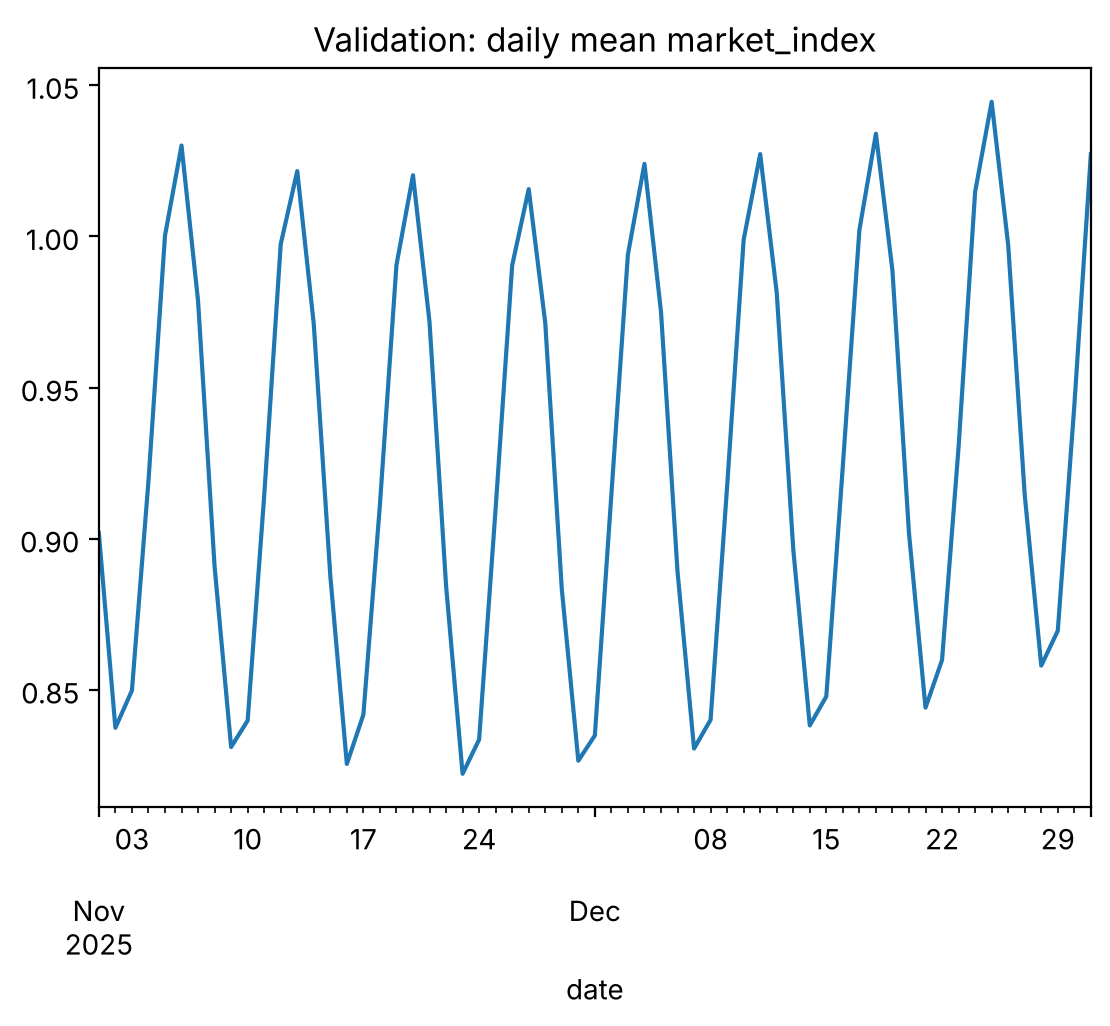

['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
          first_date  rows       lat        lon
pickup                                         
Allentown 2025-11-01    90  40.01684  -73.80889
Charlotte 2025-11-01    88  34.65272  -81.47202
Chicago   2025-11-01    75  40.51200  -86.86737
Jackson   2025-11-01   118  32.07771  -90.92587
Knoxville 2025-11-01    93  36.25725  -86.02539
Laredo    2025-11-01    89  25.50000  -97.22681
Norfolk   2025-11-01    88  37.12278  -75.87106
San Diego 2025-11-02    84  32.00929 -116.89598
     pickup_lat  pickup_lon
min    28.35765  -121.69849
max    44.30296   -69.50000


In [2]:
import matplotlib.pyplot as plt
# 1. The December question: is market_index really a clean daily value in Nov/Dec?
val = pd.read_csv("../data/validation.csv", parse_dates=["date"])
daily = val.groupby("date")["market_index"].agg(["mean", "std", "count"])
display(daily.loc["2025-12-01":"2025-12-31"].describe().round(3))
daily["mean"].plot(title="Validation: daily mean market_index"); plt.show()

# 2. The unseen cities: when do they appear, and are their coordinates in range?
train_raw = pd.read_csv("../data/train_test.csv")
unseen = sorted(set(val["pickup"]) - set(train_raw["pickup"]))
print(unseen)
print(val[val["pickup"].isin(unseen)].groupby("pickup")
      .agg(first_date=("date", "min"), rows=("date", "size"),
           lat=("pickup_lat", "first"), lon=("pickup_lon", "first")))
print(train_raw[["pickup_lat", "pickup_lon"]].describe().loc[["min", "max"]])

## Does the market's weekly cycle carry over to rates?

In [3]:
import numpy as np, matplotlib.pyplot as plt
sys.path.append("../src")
from clean import Cleaner, fit_rate_baseline, outlier_mask
from baselines import RpmBaseline
from splits import make_folds, prepare_fold

raw = pd.read_csv("../data/train_test.csv")
val = pd.read_csv("../data/validation.csv", parse_dates=["date"])

# 1. Weekly cycle in market_index: train vs validation
tr_dates = raw.assign(date=pd.to_datetime(raw["date"]))
print(pd.concat({"train": tr_dates.groupby(tr_dates["date"].dt.dayofweek)["market_index"].mean(),
                 "val": val.groupby(val["date"].dt.dayofweek)["market_index"].mean()}, axis=1).round(3))

# 2. Does the RATE have a weekly cycle? (in-sample exploration only, not scoring)
tr = Cleaner().fit(raw).transform(raw)
tr["is_outlier"] = outlier_mask(tr, fit_rate_baseline(tr))
d = tr[~tr["is_outlier"]].copy()
m = RpmBaseline([["equipment", "dist_bin"]]).fit(tr)
d["log_ratio"] = np.log(d["posted_rate"] / m.predict(d))
d["dow"] = d["date"].dt.dayofweek
print(d.groupby("dow")[["log_ratio", "market_index"]].mean().round(4))

# 3. Does the weekly part of market_index relate to the weekly part of the rate?
day = d.groupby("date").agg(lr=("log_ratio", "mean"), mi=("market_index", "mean"))
for c in ["lr", "mi"]:
    day[c + "_slow"] = day[c].rolling(7, center=True, min_periods=4).mean()
    day[c + "_wk"] = day[c] - day[c + "_slow"]
print("slow parts corr:  ", round(day["lr_slow"].corr(day["mi_slow"]), 3))
print("weekly parts corr:", round(day["lr_wk"].corr(day["mi_wk"]), 3))
print("share of daily mi variance that is weekly:", round(day["mi_wk"].var() / day["mi"].var(), 3))

# 4. Direction of the fold-3 failure: B vs D, by month and weekday
k, tr_idx, te_idx = list(make_folds(raw))[-1]
train, test, _, _ = prepare_fold(raw, tr_idx, te_idx)
from gbm import GBMModel
t = test[~test["is_outlier"]].copy()
for name, g in {"B": ["base", "weight"], "D": ["base", "weight", "market_index"]}.items():
    t["log_err"] = np.log(t["posted_rate"] / GBMModel(g).fit(train).predict(t))   # >0 = under-predicted
    print(name, "by month:", t.groupby(t["date"].dt.to_period("M"))["log_err"].mean().round(3).to_dict())
    print(name, "by weekday:", t.groupby(t["date"].dt.dayofweek)["log_err"].mean().round(3).to_dict())

      train    val
date              
0     1.000  0.846
1     1.075  0.921
2     1.153  1.002
3     1.179  1.027
4     1.134  0.980
5     1.047  0.895
6     0.989  0.835


     log_ratio  market_index
dow                         
0      -0.0087        0.9998
1      -0.0023        1.0754
2       0.0074        1.1534
3       0.0099        1.1787
4       0.0055        1.1345
5      -0.0048        1.0480
6      -0.0116        0.9887
slow parts corr:   0.683
weekly parts corr: 0.86
share of daily mi variance that is weekly: 0.187


B by month: {Period('2025-09', 'M'): 0.006, Period('2025-10', 'M'): 0.01}
B by weekday: {0: -0.002, 1: 0.006, 2: 0.013, 3: 0.017, 4: 0.016, 5: 0.006, 6: -0.001}


D by month: {Period('2025-09', 'M'): 0.05, Period('2025-10', 'M'): 0.041}
D by weekday: {0: 0.051, 1: 0.045, 2: 0.038, 3: 0.037, 4: 0.042, 5: 0.049, 6: 0.054}


## Why does `quote_signal` help in some folds and hurt in others?

In [4]:
import numpy as np
from splits import make_folds, prepare_fold
from gbm import GBMModel

parts = []
for k, tr_idx, te_idx in make_folds(raw):
    train, test, _, _ = prepare_fold(raw, tr_idx, te_idx)
    b = GBMModel(["base", "weight"]).fit(train)
    t = test[~test["is_outlier"]].copy()
    t["resid"] = np.log(t["posted_rate"] / b.predict(t))     # >0 = under-predicted by B
    t["fold"] = k
    parts.append(t)
r = pd.concat(parts)

# 1. Shape of the relationship, per fold
r["qs_bin"] = pd.qcut(r["quote_signal"], 10)
print(r.pivot_table(index="qs_bin", columns="fold", values="resid",
                    aggfunc="mean", observed=True).round(3))

# 2. Monthly level vs row-level deviation
r["month"] = r["date"].dt.to_period("M")
print(r.groupby(["fold", "month"])[["resid", "quote_signal"]].mean().round(3))
r["qs_dev"] = r["quote_signal"] - r.groupby("month")["quote_signal"].transform("mean")
for k, d in r.groupby("fold"):
    print(k, "row-level corr:", round(d["resid"].corr(d["qs_dev"]), 3),
          "| raw corr:", round(d["resid"].corr(d["quote_signal"]), 3))

fold                1      2      3
qs_bin                             
(0.691, 1.697]  0.056  0.024  0.025
(1.697, 1.836]  0.048  0.011  0.008
(1.836, 1.923]  0.052  0.011  0.002
(1.923, 1.993]  0.050  0.007  0.000
(1.993, 2.055]  0.051  0.008  0.003
(2.055, 2.118]  0.052  0.006  0.001
(2.118, 2.182]  0.054  0.002  0.005
(2.182, 2.261]  0.058  0.003  0.005
(2.261, 2.397]  0.065 -0.003  0.008
(2.397, 3.61]   0.083 -0.006  0.025
              resid  quote_signal
fold month                       
1    2025-05  0.047         1.913
     2025-06  0.071         2.297
2    2025-07  0.022         1.923
     2025-08 -0.007         2.053
3    2025-09  0.006         2.200
     2025-10  0.010         1.943
1 row-level corr: 0.076 | raw corr: 0.258
2 row-level corr: -0.116 | raw corr: -0.215
3 row-level corr: 0.061 | raw corr: 0.035


## Shuffle test: is the `quote_signal` gain real?
If scrambling it barely changes the error, the model wasn't really using it.

In [5]:
import numpy as np, pandas as pd
from clean import DIST_BINS
from splits import make_folds, prepare_fold
from gbm import GBMModel

SETS = {"B": ["base", "weight"], "I": ["base", "weight", "quote_signal"]}
parts, shuffled = [], []
rng = np.random.default_rng(0)

for k, tr_idx, te_idx in make_folds(raw):
    train, test, _, _ = prepare_fold(raw, tr_idx, te_idx)
    t = test[~test["is_outlier"]].copy()
    models = {n: GBMModel(g).fit(train) for n, g in SETS.items()}
    for n, m in models.items():
        t["pred_" + n] = m.predict(t)
        t["ae_" + n] = (t["posted_rate"] - t["pred_" + n]).abs()
        t["le_" + n] = np.log(t["posted_rate"] / t["pred_" + n])
    t["fold"] = k
    parts.append(t)

    # Permutation test: scramble quote_signal in the test rows only
    ts = t.copy()
    ts["quote_signal"] = rng.permutation(ts["quote_signal"].to_numpy())
    ae_shuf = (ts["posted_rate"] - models["I"].predict(ts)).abs().mean()
    shuffled.append({"fold": k, "MAE B": t["ae_B"].mean(), "MAE I": t["ae_I"].mean(),
                     "MAE I with shuffled quote_signal": ae_shuf})

c = pd.concat(parts)
c["gain"] = c["ae_B"] - c["ae_I"]                      # >0 means I is better
c["dist_bin"] = pd.cut(c["distance"], DIST_BINS)
c["qs_bin"] = pd.qcut(c["quote_signal"], 5)
c["w_bin"] = pd.qcut(c["weight"], 5)
c["dow"] = c["date"].dt.dayofweek

print("1. Shuffle test"); display(pd.DataFrame(shuffled).set_index("fold").round(1))

print("2. Bias or spread? (log error)")
display(c.groupby("fold").agg(B_bias=("le_B", "mean"), I_bias=("le_I", "mean"),
                              B_std=("le_B", "std"), I_std=("le_I", "std")).round(4))

for col in ["equipment", "dist_bin", "w_bin", "qs_bin", "dow"]:
    print(f"3. Mean gain (MAE_B - MAE_I) by {col}")
    display(c.pivot_table(index=col, columns="fold", values="gain", aggfunc="mean", observed=True).round(1))

1. Shuffle test


,MAE B,MAE I,MAE I with shuffled quote_signal
fold,,,
1,144.4,61.7,167.5
2,66.5,89.5,138.5
3,59.0,35.6,92.5


2. Bias or spread? (log error)


,B_bias,I_bias,B_std,I_std
fold,,,,
1,0.0590,0.0193,0.0355,0.0293
2,0.0079,0.0111,0.0364,0.0654
3,0.0081,0.0022,0.0337,0.0201


3. Mean gain (MAE_B - MAE_I) by equipment


fold,1,2,3
equipment,,,
Dry Van,81.5,-17.4,19.7
Flatbed,76.5,-28.5,28.7
Reefer,89.9,-31.5,27.8


... (4 outputs left out)

3. Mean gain (MAE_B - MAE_I) by qs_bin


fold,1,2,3
qs_bin,,,
"(0.691, 1.836]",53.3,-5.3,29.7
"(1.836, 1.993]",61.1,-26.0,15.4
"(1.993, 2.118]",99.4,-29.7,23.0
"(2.118, 2.261]",90.4,-17.2,16.7
"(2.261, 3.61]",97.9,-51.2,32.6


3. Mean gain (MAE_B - MAE_I) by dow


fold,1,2,3
dow,,,
0,77.0,-25.0,21.3
1,78.3,-23.9,23.5
2,92.9,-9.5,24.4
3,95.9,-11.9,26.2
4,82.4,-27.6,26.9
5,80.7,-29.4,18.9
6,72.7,-34.4,22.0


## How does the rate relate to `quote_signal`, month by month?

In [6]:
import numpy as np, pandas as pd
from clean import Cleaner, fit_rate_baseline, outlier_mask
from baselines import RpmBaseline

# 1. Gain by test month (c comes from the previous cell)
c["month"] = c["date"].dt.to_period("M")
m = c.groupby(["fold", "month"])[["ae_B", "ae_I"]].mean()
m["gain"] = m["ae_B"] - m["ae_I"]
print("1. Gain by test month"); display(m.round(1))

# 2. In-sample, month by month: how does the rate relate to quote_signal?
#    (exploration only, nothing here is scored)
tr = Cleaner().fit(raw).transform(raw)
tr["is_outlier"] = outlier_mask(tr, fit_rate_baseline(tr))
d = tr[~tr["is_outlier"]].copy()
d["log_ratio"] = np.log(d["posted_rate"] / RpmBaseline([["equipment", "dist_bin"]]).fit(tr).predict(d))
d["month"] = d["date"].dt.to_period("M")
d["qs_c"] = d["quote_signal"] - d["quote_signal"].mean()
d["w_c"] = (d["weight"] - d["weight"].mean()) / 10000

rows = []
for mo, g in d.groupby("month"):
    X = np.column_stack([np.ones(len(g)), g["w_c"], g["qs_c"], g["qs_c"] ** 2])
    beta = np.linalg.lstsq(X, g["log_ratio"].to_numpy(), rcond=None)[0]
    rows.append({"month": mo, "n": len(g), "qs_mean": g["quote_signal"].mean(),
                 "qs_linear": beta[2], "qs_squared": beta[3]})
print("2. Per-month fit: log_ratio ~ weight + qs + qs^2")
display(pd.DataFrame(rows).set_index("month").round(4))

# 3. What explains quote_signal itself? Share of its variance by grouping
d["dow"] = d["date"].dt.dayofweek
tot = d["quote_signal"].var()
print("3. Share of quote_signal variance explained by group means")
for col in ["month", "date", "dow", "equipment", "pickup"]:
    print(f"  {col:10s}", round(d.groupby(col)["quote_signal"].transform("mean").var() / tot, 3))

1. Gain by test month


ae_B   ae_I   gain
fold month                       
1    2025-05  116.1   61.4   54.7
     2025-06  173.5   62.0  111.5
2    2025-07   77.6   51.4   26.3
     2025-08   55.1  128.8  -73.8
3    2025-09   60.8   31.3   29.6
     2025-10   57.3   39.9   17.5

2. Per-month fit: log_ratio ~ weight + qs + qs^2


,n,qs_mean,qs_linear,qs_squared
month,,,,
2025-01,4837,2.0676,0.0472,0.0372
2025-02,4280,2.0959,0.0462,0.0394
2025-03,4965,2.1793,0.0629,0.0145
2025-04,4753,1.9645,-0.0441,0.0184
2025-05,4851,1.9134,-0.0280,0.0292
2025-06,4720,2.2968,0.0461,0.0156
2025-07,4847,1.9226,-0.0386,0.0174
2025-08,4691,2.0526,-0.0023,0.0027
2025-09,4606,2.2002,0.0567,0.0209


3. Share of quote_signal variance explained by group means
  month      0.184
  date       0.198


  dow        0.001
  equipment  0.004


  pickup     0.002


## Error by test month for the main candidates

In [7]:
import numpy as np, pandas as pd
from splits import make_folds, prepare_fold
from gbm import GBMModel

SETS = {
    "B": ["base", "weight"],
    "M": ["base", "weight", "dow"],
    "I": ["base", "weight", "quote_signal"],
    "P": ["base", "weight", "qs_month"],
    "G": ["base", "weight", "market_index", "month"],
}
rows = []
for k, tr_idx, te_idx in make_folds(raw):
    train, test, _, _ = prepare_fold(raw, tr_idx, te_idx)
    t = test[~test["is_outlier"]].copy()
    t["month"] = t["date"].dt.to_period("M")
    for name, groups in SETS.items():
        pred = GBMModel(groups).fit(train).predict(t)
        ae = (t["posted_rate"] - pred).abs()
        for mo, v in ae.groupby(t["month"]).mean().items():
            rows.append({"model": name, "month": mo, "MAE_clean": v})

display(pd.DataFrame(rows).pivot(index="month", columns="model", values="MAE_clean").round(1))

model,B,G,I,M,P
month,,,,,
2025-05,116.1,54.6,61.4,114.9,58.0
2025-06,173.5,98.2,62.0,174.7,132.6
2025-07,77.6,67.4,51.4,74.9,28.0
2025-08,55.1,74.1,128.8,52.6,161.9
2025-09,60.8,76.7,31.3,59.3,29.9
2025-10,57.3,66.9,39.9,54.9,32.9


## What I decided

- **Weight helps everywhere** (B vs A), so it stays.
- **`market_index` is unstable.** It helps a lot in fold 1 (the May–Jun peak) but makes fold 3 much worse (D: 110 vs B: 59). Its link to rates shifts over the year, and Sep–Oct, the period closest to Nov–Dec, is where it fails. The smoothed version (J, K, L) is no better. Left out.
- **`quote_signal` is the best feature on average but flips sign by month** (cells above). It gives the best fold 3 (T: 32) but makes fold 2 worse (T: 83 vs S: 52), and its month-by-month slope changes direction. Too unpredictable for an unseen period, so I left it out.
- **Coordinates help in every fold** (S vs M: 142 / 52 / 42 vs 144 / 64 / 57) and cut the unseen-city error from 63 to 49. They're the only geography the model has for the 8 new cities. Kept.
- **Month number** (G, O) can't help: the model has never seen November or December.

**Final feature set: S** = distance, equipment, weight (+ flags), day of week, coordinates. It was never the worst in any fold and it improves on the unseen cities.